In [12]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

con = sqlite3.connect("../oulad.db")
student_info = pd.read_csv("../data/studentInfo.csv")

In [13]:
import pandas as pd
print(pd.__version__)


2.2.2


In [14]:
import urllib.request
import zipfile
import hashlib
from pathlib import Path

DATA = Path("../data")
DATA.mkdir(exist_ok=True)

URL = "https://ndownloader.figshare.com/files/8606371"
ZIP_PATH = DATA / "anonymisedData.zip"

urllib.request.urlretrieve(URL, ZIP_PATH)
print("Taille (octets) :", ZIP_PATH.stat().st_size)

md5 = hashlib.md5(ZIP_PATH.read_bytes()).hexdigest()
print("Fichier intact :", md5 == "7412686fd77cf0e0ee1e8c3e9b354308")

with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(DATA)

print(sorted(p.name for p in DATA.glob("*.csv")))

Taille (octets) : 46750706
Fichier intact : True
['assessments.csv', 'courses.csv', 'studentAssessment.csv', 'studentInfo.csv', 'studentRegistration.csv', 'studentVle.csv', 'vle.csv']


In [15]:
import pandas as pd

student_info = pd.read_csv(DATA / "studentInfo.csv")
print(student_info.shape)
student_info.head()


(32593, 12)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [16]:
print(student_info.shape)
student_info.info()

(32593, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   code_module           32593 non-null  object
 1   code_presentation     32593 non-null  object
 2   id_student            32593 non-null  int64 
 3   gender                32593 non-null  object
 4   region                32593 non-null  object
 5   highest_education     32593 non-null  object
 6   imd_band              31482 non-null  object
 7   age_band              32593 non-null  object
 8   num_of_prev_attempts  32593 non-null  int64 
 9   studied_credits       32593 non-null  int64 
 10  disability            32593 non-null  object
 11  final_result          32593 non-null  object
dtypes: int64(3), object(9)
memory usage: 3.0+ MB


In [18]:
student_info["final_result"].value_counts()

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

In [19]:
student_info.isna().sum()

code_module                0
code_presentation          0
id_student                 0
gender                     0
region                     0
highest_education          0
imd_band                1111
age_band                   0
num_of_prev_attempts       0
studied_credits            0
disability                 0
final_result               0
dtype: int64

In [20]:
student_info["final_result"].value_counts(normalize=True)*100

final_result
Pass           37.925321
Withdrawn      31.160065
Fail           21.636548
Distinction     9.278066
Name: proportion, dtype: float64

In [21]:
student_info["abandon"]=(student_info["final_result"]=="Withdrawn")

In [23]:
student_info.groupby("code_module")["abandon"].mean()*100

code_module
AAA    16.844920
BBB    30.193450
CCC    44.542174
DDD    35.873724
EEE    24.608044
FFF    30.958516
GGG    11.523283
Name: abandon, dtype: float64

In [25]:
student_info.groupby("gender")["abandon"].mean()*100

gender
F    30.479685
M    31.720280
Name: abandon, dtype: float64

In [26]:
vle_sample = pd.read_csv("../data/studentVle.csv", nrows=5)
vle_sample

,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
3,AAA,2013J,28400,546614,-10,11
4,AAA,2013J,28400,546714,-10,1


In [27]:
student_vle = pd.read_csv("../data/studentVle.csv")
print(student_vle.shape)
student_vle.dtypes

(10655280, 6)


code_module          object
code_presentation    object
id_student            int64
id_site               int64
date                  int64
sum_click             int64
dtype: object

In [28]:
student_info.duplicated(subset=["code_module", "code_presentation", "id_student"]).sum()
student_info["id_student"].duplicated().sum()

3808

In [29]:
student_info.duplicated(subset=["code_module", "code_presentation", "id_student"]).sum()

0

In [30]:
student_info["id_student"].duplicated().sum()

3808

In [31]:
vle_sample

,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
3,AAA,2013J,28400,546614,-10,11
4,AAA,2013J,28400,546714,-10,1


In [32]:
student_vle["date"].min(), student_vle["date"].max()
student_vle["sum_click"].describe() 

count    1.065528e+07
mean     3.716946e+00
std      8.849047e+00
min      1.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      3.000000e+00
max      6.977000e+03
Name: sum_click, dtype: float64

In [33]:
student_vle["date"].min(), student_vle["date"].max()

(-25, 269)

In [34]:
student_vle["sum_click"].describe() 

count    1.065528e+07
mean     3.716946e+00
std      8.849047e+00
min      1.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      3.000000e+00
max      6.977000e+03
Name: sum_click, dtype: float64

In [35]:
student_vle["semaine"] = student_vle["date"] // 7

In [36]:
student_vle.groupby("semaine")["sum_click"].sum().head(10)

semaine
-4      43298
-3     433407
-2     646001
-1    1025241
 0    2013077
 1    1797648
 2    2307080
 3    1663598
 4    1505334
 5    1228901
Name: sum_click, dtype: int64

In [37]:
precoce = student_vle[(student_vle["date"] >= 0) & (student_vle["date"] < 28)]

clics_precoces = (
    precoce
    .groupby(["code_module", "code_presentation", "id_student"])["sum_click"]
    .sum()
    .reset_index()
)
print(clics_precoces.shape)
clics_precoces.head()

(27886, 4)


,code_module,code_presentation,id_student,sum_click
0,AAA,2013J,11391,303
1,AAA,2013J,28400,335
2,AAA,2013J,30268,179
3,AAA,2013J,31604,309
4,AAA,2013J,32885,272


In [38]:
clics_precoces = clics_precoces.rename(columns={"sum_click": "clics_4sem"})

base = student_info.merge(
    clics_precoces,
    on=["code_module", "code_presentation", "id_student"],
    how="left"
)

print(base.shape)
base["clics_4sem"].isna().sum()

(32593, 14)


4707

In [39]:
base["clics_4sem"] = base["clics_4sem"].fillna(0)
base["aucun_clic"] = base["clics_4sem"] == 0
base.groupby("aucun_clic")["abandon"].mean() * 100

aucun_clic
False    22.936240
True     79.881028
Name: abandon, dtype: float64

In [40]:
import sqlite3
import pandas as pd
from pathlib import Path

DATA = Path("../data")
con = sqlite3.connect("../oulad.db")

for f in sorted(DATA.glob("*.csv")):
    for i, morceau in enumerate(pd.read_csv(f, chunksize=500_000)):
        morceau.to_sql(f.stem, con, if_exists="replace" if i == 0 else "append", index=False)
    print(f.stem, "chargé")

con.execute("CREATE INDEX IF NOT EXISTS idx_vle ON studentVle(code_module, code_presentation, id_student, date)")
con.commit()

assessments chargé
courses chargé
studentAssessment chargé
studentInfo chargé
studentRegistration chargé
studentVle chargé
vle chargé


In [41]:
requete = """
SELECT code_module,
       COUNT(*) AS inscrits,
       SUM(CASE WHEN final_result = 'Withdrawn' THEN 1 ELSE 0 END) AS abandons,
       ROUND(100.0 * SUM(CASE WHEN final_result = 'Withdrawn' THEN 1 ELSE 0 END) / COUNT(*), 1) AS taux_abandon
FROM studentInfo
GROUP BY code_module
ORDER BY taux_abandon DESC;
"""
pd.read_sql(requete, con)

,code_module,inscrits,abandons,taux_abandon
0,CCC,4434,1975,44.5
1,DDD,6272,2250,35.9
2,FFF,7762,2403,31.0
3,BBB,7909,2388,30.2
4,EEE,2934,722,24.6
5,AAA,748,126,16.8
6,GGG,2534,292,11.5


In [42]:
requete = """
WITH clics AS (
    SELECT code_module, code_presentation, id_student,
           SUM(sum_click) AS clics_4sem
    FROM studentVle
    WHERE date >= 0 AND date < 28
    GROUP BY code_module, code_presentation, id_student
)
SELECT s.final_result,
       COUNT(*) AS etudiants,
       SUM(CASE WHEN c.clics_4sem IS NULL THEN 1 ELSE 0 END) AS sans_clic,
       ROUND(AVG(COALESCE(c.clics_4sem, 0)), 1) AS clics_moyens
FROM studentInfo s
LEFT JOIN clics c
  ON  s.code_module = c.code_module
  AND s.code_presentation = c.code_presentation
  AND s.id_student = c.id_student
GROUP BY s.final_result;
"""
pd.read_sql(requete, con)

,final_result,etudiants,sans_clic,clics_moyens
0,Distinction,3024,30,427.2
1,Fail,7052,715,176.4
2,Pass,12361,202,317.2
3,Withdrawn,10156,3760,130.5


In [43]:
pd.read_sql("PRAGMA table_info(studentRegistration)", con)

,cid,name,type,notnull,dflt_value,pk
0,0,code_module,TEXT,0,None,0
1,1,code_presentation,TEXT,0,None,0
2,2,id_student,INTEGER,0,None,0
3,3,date_registration,REAL,0,None,0
4,4,date_unregistration,REAL,0,None,0


In [44]:
pd.read_sql("SELECT * FROM studentRegistration LIMIT 5", con)

,code_module,code_presentation,id_student,date_registration,date_unregistration
0,AAA,2013J,11391,-159.0,NaN
1,AAA,2013J,28400,-53.0,NaN
2,AAA,2013J,30268,-92.0,12.0
3,AAA,2013J,31604,-52.0,NaN
4,AAA,2013J,32885,-176.0,NaN


In [45]:
requete = """
WITH clics AS (
    SELECT code_module, code_presentation, id_student,
           SUM(sum_click) AS clics_4sem
    FROM studentVle
    WHERE date >= 0 AND date < 28
    GROUP BY code_module, code_presentation, id_student
),
base AS (
    SELECT s.final_result, c.clics_4sem
    FROM studentInfo s
    JOIN studentRegistration r
      ON  s.code_module = r.code_module
      AND s.code_presentation = r.code_presentation
      AND s.id_student = r.id_student
    LEFT JOIN clics c
      ON  s.code_module = c.code_module
      AND s.code_presentation = c.code_presentation
      AND s.id_student = c.id_student
    WHERE r.date_unregistration IS NULL OR r.date_unregistration >= 28
)
SELECT CASE WHEN clics_4sem IS NULL THEN 'aucun clic' ELSE 'au moins 1 clic' END AS groupe,
       COUNT(*) AS etudiants,
       ROUND(100.0 * SUM(CASE WHEN final_result = 'Withdrawn' THEN 1 ELSE 0 END) / COUNT(*), 1) AS taux_abandon
FROM base
GROUP BY groupe;
"""
pd.read_sql(requete, con)

,groupe,etudiants,taux_abandon
0,au moins 1 clic,26304,18.3
1,aucun clic,1249,24.3


In [48]:
requete = """
WITH effectifs AS (
    SELECT final_result, COUNT(*) AS n
    FROM studentInfo
    GROUP BY final_result
),
hebdo AS (
    SELECT s.final_result, v.date / 7 AS semaine, SUM(v.sum_click) AS clics
    FROM studentVle v
    JOIN studentInfo s
      ON  s.code_module = v.code_module
      AND s.code_presentation = v.code_presentation
      AND s.id_student = v.id_student
    WHERE v.date >= 0 AND v.date < 168
    GROUP BY s.final_result, semaine
) 
SELECT h.final_result, h.semaine,
       ROUND(1.0 * h.clics / e.n, 1) AS clics_par_etudiant,
       ROUND(SUM(1.0 * h.clics / e.n) OVER (PARTITION BY h.final_result ORDER BY h.semaine), 1) AS cumul
FROM hebdo h
JOIN effectifs e USING (final_result)
ORDER BY h.final_result, h.semaine;
"""
semaines = pd.read_sql(requete, con)
semaines.head(12)


,final_result,semaine,clics_par_etudiant,cumul
0,Distinction,0,113.6,113.6
1,Distinction,1,101.5,215.1
2,Distinction,2,117.9,333.0
3,Distinction,3,94.3,427.2
4,Distinction,4,87.4,514.6
5,Distinction,5,73.7,588.3
6,Distinction,6,82.2,670.5
7,Distinction,7,78.1,748.6
8,Distinction,8,64.2,812.8
9,Distinction,9,71.4,884.2


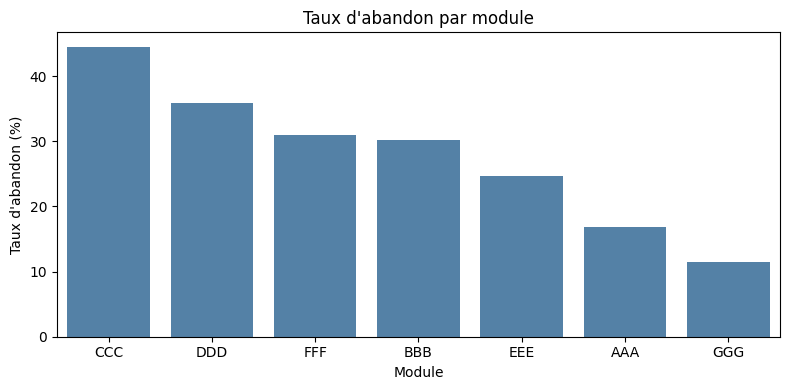

In [49]:
taux = pd.read_sql("""
    SELECT code_module,
           ROUND(100.0 * SUM(CASE WHEN final_result = 'Withdrawn' THEN 1 ELSE 0 END) / COUNT(*), 1) AS taux_abandon
    FROM studentInfo
    GROUP BY code_module
    ORDER BY taux_abandon DESC
""", con)

plt.figure(figsize=(8, 4))
sns.barplot(data=taux, x="code_module", y="taux_abandon", color="steelblue")
plt.title("Taux d'abandon par module")
plt.xlabel("Module")
plt.ylabel("Taux d'abandon (%)")
plt.tight_layout()
plt.savefig("../images/abandon_par_module.png", dpi=150)
plt.show()

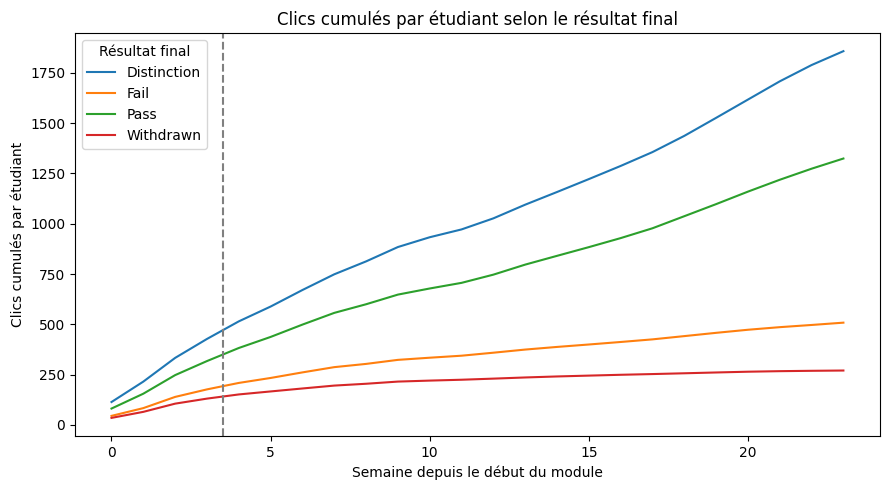

In [50]:
plt.figure(figsize=(9, 5))
sns.lineplot(data=semaines, x="semaine", y="cumul", hue="final_result")
plt.axvline(x=3.5, linestyle="--", color="gray")
plt.title("Clics cumulés par étudiant selon le résultat final")
plt.xlabel("Semaine depuis le début du module")
plt.ylabel("Clics cumulés par étudiant")
plt.legend(title="Résultat final")
plt.tight_layout()
plt.savefig("../images/clics_cumules.png", dpi=150)
plt.show()

In [51]:
requete = """
WITH clics AS (
    SELECT code_module, code_presentation, id_student,
           SUM(sum_click) AS clics_4sem
    FROM studentVle
    WHERE date >= 0 AND date < 28
    GROUP BY code_module, code_presentation, id_student
),
base AS (
    SELECT s.final_result, COALESCE(c.clics_4sem, 0) AS clics_4sem
    FROM studentInfo s
    JOIN studentRegistration r
      ON  s.code_module = r.code_module
      AND s.code_presentation = r.code_presentation
      AND s.id_student = r.id_student
    LEFT JOIN clics c
      ON  s.code_module = c.code_module
      AND s.code_presentation = c.code_presentation
      AND s.id_student = c.id_student
    WHERE r.date_unregistration IS NULL OR r.date_unregistration >= 28
)
SELECT CASE WHEN clics_4sem = 0   THEN '1) 0 clic'
            WHEN clics_4sem <= 50  THEN '2) 1-50'
            WHEN clics_4sem <= 150 THEN '3) 51-150'
            WHEN clics_4sem <= 400 THEN '4) 151-400'
            ELSE '5) plus de 400' END AS tranche,
       COUNT(*) AS etudiants,
       ROUND(100.0 * SUM(CASE WHEN final_result = 'Withdrawn' THEN 1 ELSE 0 END) / COUNT(*), 1) AS taux_abandon
FROM base
GROUP BY tranche
ORDER BY tranche;
"""
tranches = pd.read_sql(requete, con)
tranches

,tranche,etudiants,taux_abandon
0,1) 0 clic,1249,24.3
1,2) 1-50,4444,21.5
2,3) 51-150,6718,21.1
3,4) 151-400,8985,17.9
4,5) plus de 400,6157,13.7


In [52]:
def taux_par(colonne):
    return pd.read_sql(f"""
        SELECT {colonne} AS categorie,
               COUNT(*) AS etudiants,
               ROUND(100.0 * SUM(CASE WHEN final_result = 'Withdrawn' THEN 1 ELSE 0 END) / COUNT(*), 1) AS taux_abandon
        FROM studentInfo
        GROUP BY {colonne}
        ORDER BY taux_abandon DESC
    """, con)

taux_par("age_band")

,categorie,etudiants,taux_abandon
0,0-35,22944,32.2
1,35-55,9433,28.8
2,55<=,216,25.0


In [53]:
clics = pd.read_sql("""
    SELECT s.final_result, COALESCE(c.clics_4sem, 0) AS clics_4sem
    FROM studentInfo s
    LEFT JOIN (
        SELECT code_module, code_presentation, id_student, SUM(sum_click) AS clics_4sem
        FROM studentVle
        WHERE date >= 0 AND date < 28
        GROUP BY code_module, code_presentation, id_student
    ) c
      ON  s.code_module = c.code_module
      AND s.code_presentation = c.code_presentation
      AND s.id_student = c.id_student
""", con)

clics.groupby("final_result")["clics_4sem"].median()

final_result
Distinction    299.0
Fail           103.0
Pass           217.0
Withdrawn       36.0
Name: clics_4sem, dtype: float64

In [54]:
from pathlib import Path
Path("../powerbi").mkdir(exist_ok=True)

requete = """
WITH clics AS (
    SELECT code_module, code_presentation, id_student, SUM(sum_click) AS clics_4sem
    FROM studentVle
    WHERE date >= 0 AND date < 28
    GROUP BY code_module, code_presentation, id_student
)
SELECT s.code_module, s.code_presentation, s.id_student,
       s.gender, s.region, s.highest_education, s.imd_band, s.age_band,
       s.final_result,
       CASE WHEN s.final_result = 'Withdrawn' THEN 1 ELSE 0 END AS abandon,
       COALESCE(c.clics_4sem, 0) AS clics_4sem,
       CASE WHEN COALESCE(c.clics_4sem, 0) = 0 THEN '1) 0 clic'
            WHEN c.clics_4sem <= 50  THEN '2) 1-50'
            WHEN c.clics_4sem <= 150 THEN '3) 51-150'
            WHEN c.clics_4sem <= 400 THEN '4) 151-400'
            ELSE '5) plus de 400' END AS tranche_clics,
       CASE WHEN r.date_unregistration IS NULL OR r.date_unregistration >= 28
            THEN 1 ELSE 0 END AS inscrit_j28
FROM studentInfo s
JOIN studentRegistration r
  ON  s.code_module = r.code_module
  AND s.code_presentation = r.code_presentation
  AND s.id_student = r.id_student
LEFT JOIN clics c
  ON  s.code_module = c.code_module
  AND s.code_presentation = c.code_presentation
  AND s.id_student = c.id_student
"""
etudiants = pd.read_sql(requete, con)
print(etudiants.shape)

etudiants.to_csv("../powerbi/etudiants.csv", index=False)
semaines.to_csv("../powerbi/clics_hebdo.csv", index=False)

(32593, 13)
